# ORBITGUARD Stage 6: Explainable AI with SHAP

This notebook explains the saved **baseline XGBoost** model without retraining it or changing any predictions. It uses the exact Stage 3 preprocessing saved with the Stage 4 model, and the 18 feature names in the saved feature contract. It explains a deterministic sample of official test records using a sampled training background. The target and split are never model inputs.

SHAP describes how this model uses its input features. It does **not** show that a feature caused a physical satellite fault.

## 1. Explainable AI and SHAP in simple English

- **Explainable AI (XAI)** means methods that help people inspect how a trained model arrived at a prediction.
- **SHAP** (SHapley Additive exPlanations) assigns each input feature a contribution to one model output, relative to a baseline prediction.
- A **SHAP value** is that feature's contribution for a particular record. The values add to the model output relative to the SHAP baseline.
- Here we explain **the probability of class 1 (anomaly)**. A positive SHAP value moves the prediction toward a higher anomaly probability; a negative value moves it toward a lower anomaly probability. This sign is about the model score, not physical harm or safety.

SHAP is useful in satellite anomaly work because it can summarize which telemetry features the classifier relied on globally and show how features contributed to one alert or one normal prediction. It can help guide review, but it does not prove a feature caused a spacecraft condition or replace operator judgment.

## 2. Load the saved model, preprocessing, and feature contract

The baseline model artifact is a saved pipeline containing a classifier and the Stage 3 imputer. The module separately loads the Stage 3 preprocessor and checks both versions agree. It verifies the feature names against the saved feature file, computes the pipeline predictions and the direct preprocessed-classifier predictions, and stops if they do not match.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display, Image

current_path = Path.cwd().resolve()
if current_path.name.lower() == "notebooks":
    current_path = current_path.parent
PROJECT_ROOT = next(
    (candidate for candidate in (current_path, *current_path.parents)
     if (candidate / "src" / "explainability.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find ORBITGUARD (src/explainability.py). Open this notebook "
        "from the project or clone it in Google Colab."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.explainability import explain_baseline_xgboost

MODEL_DIR = PROJECT_ROOT / "models"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
SUMMARY_DIR = PROJECT_ROOT / "reports" / "evaluation"

explanations = explain_baseline_xgboost(
    model_dir=MODEL_DIR,
    processed_dir=PROCESSED_DIR,
    figures_dir=FIGURES_DIR,
    summary_dir=SUMMARY_DIR,
    raw_dataset_path=PROJECT_ROOT / "data" / "raw" / "dataset.csv",
    background_rows=80,
    explanation_rows=96,
    random_state=42,
)

print("Model explained: saved baseline XGBoost; no retraining performed.")
print(f"SHAP training background rows: {explanations['background_rows']}")
print(f"Official test rows explained: {explanations['explanation_rows']}")
print(f"Maximum SHAP additivity error: "
      f"{explanations['summary']['additivity_max_absolute_error']:.3g}")
print("Prediction equivalence and class-1 probability additivity checks passed.")

C:\Users\HP\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model explained: saved baseline XGBoost; no retraining performed.
SHAP training background rows: 80
Official test rows explained: 96
Maximum SHAP additivity error: 1.05e-07
Prediction equivalence and class-1 probability additivity checks passed.


<Figure size 640x480 with 0 Axes>

## 3. Global SHAP importance and beeswarm summary

The bar plot ranks features by their average absolute SHAP contribution across the explained test sample. It shows typical contribution size, not whether a feature raises or lowers anomaly probability. The beeswarm plot shows individual records: horizontal position and color help show direction and feature value. Each point represents a test record from the selected sample.

Global importance: mean absolute SHAP contribution


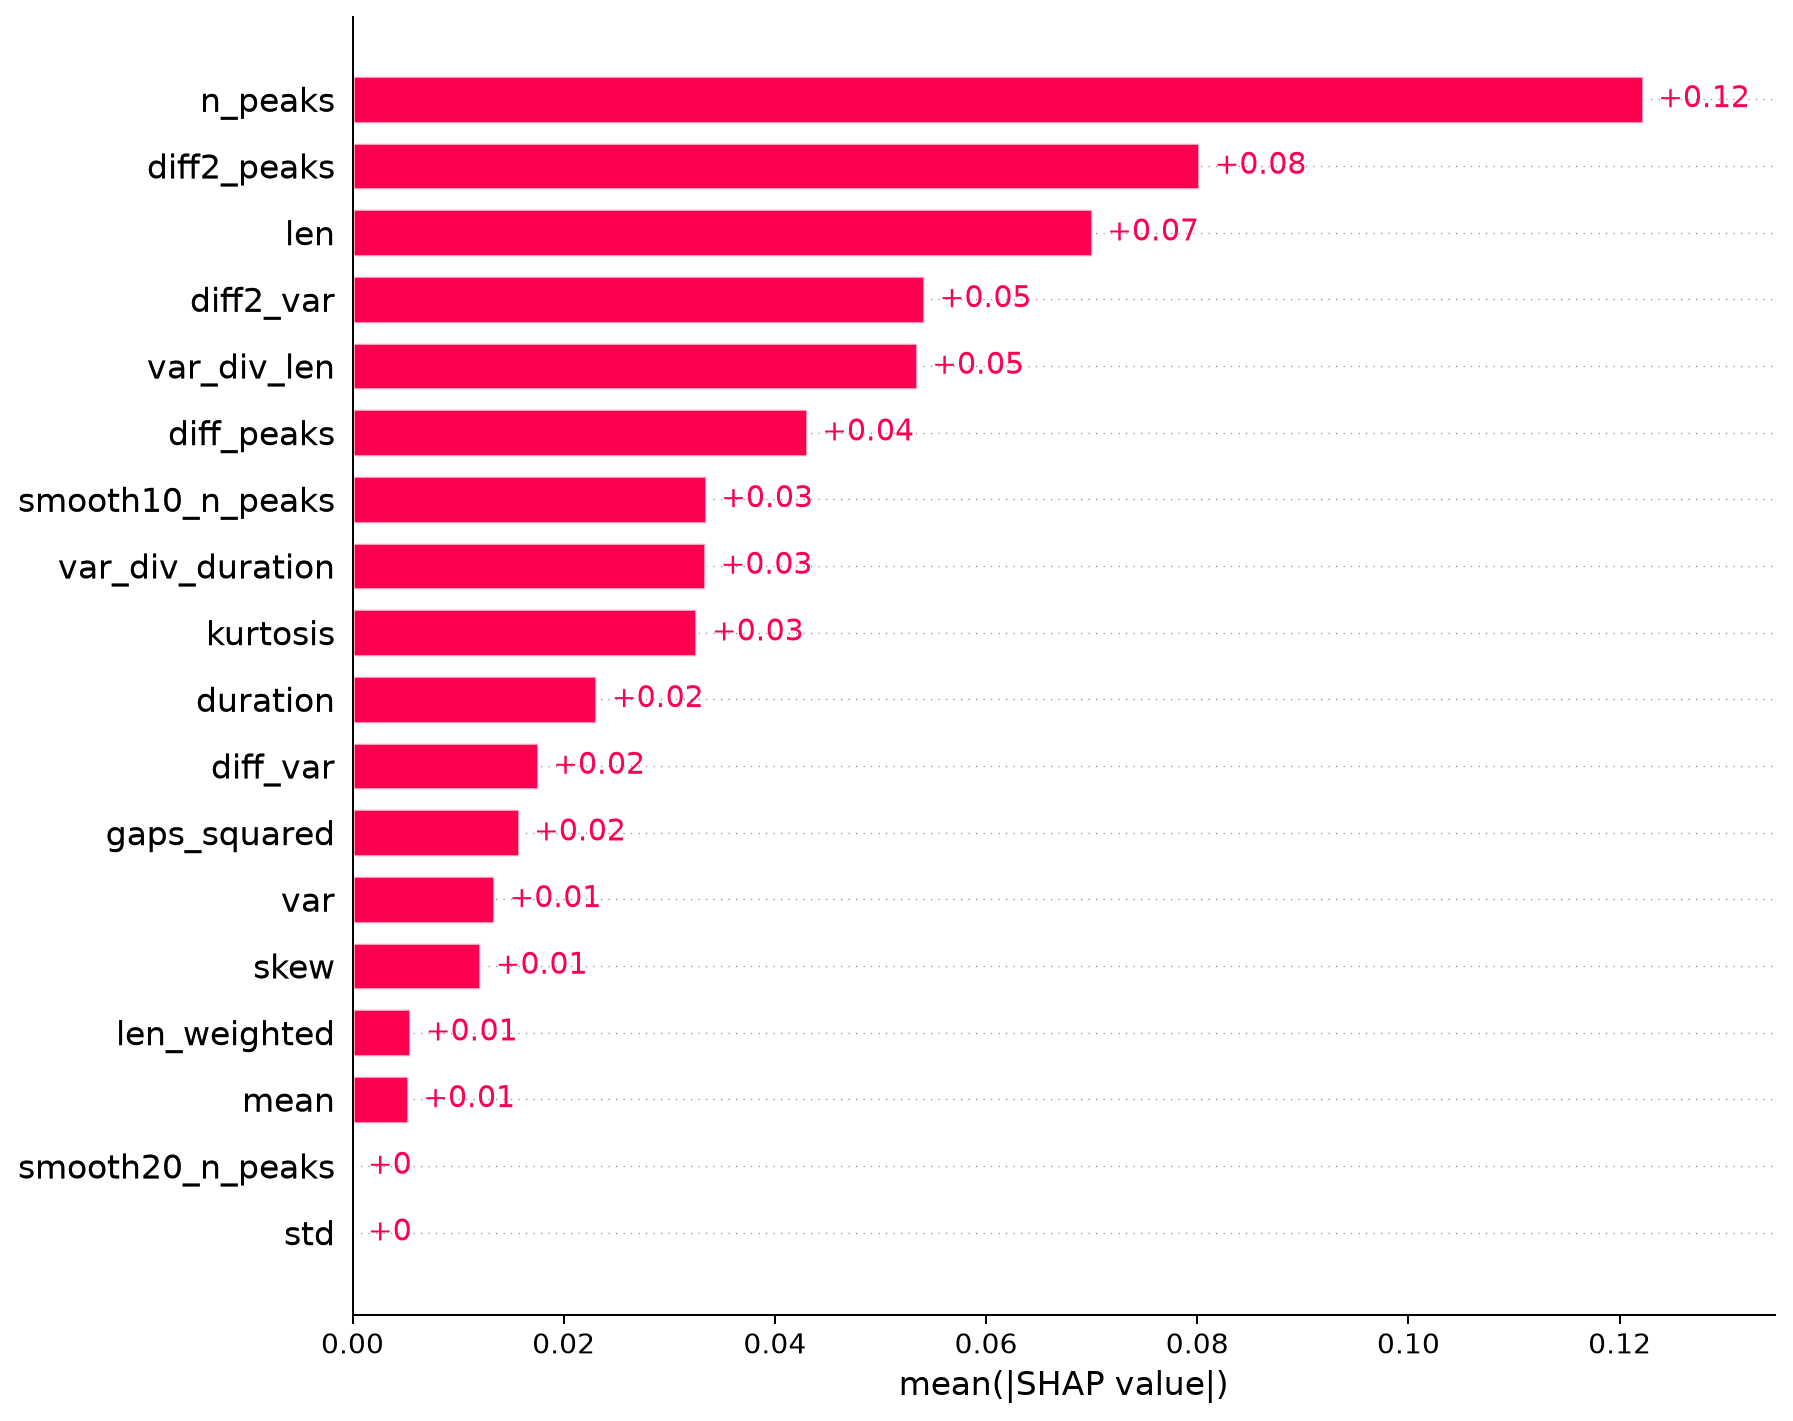

SHAP summary: individual contributions and feature values


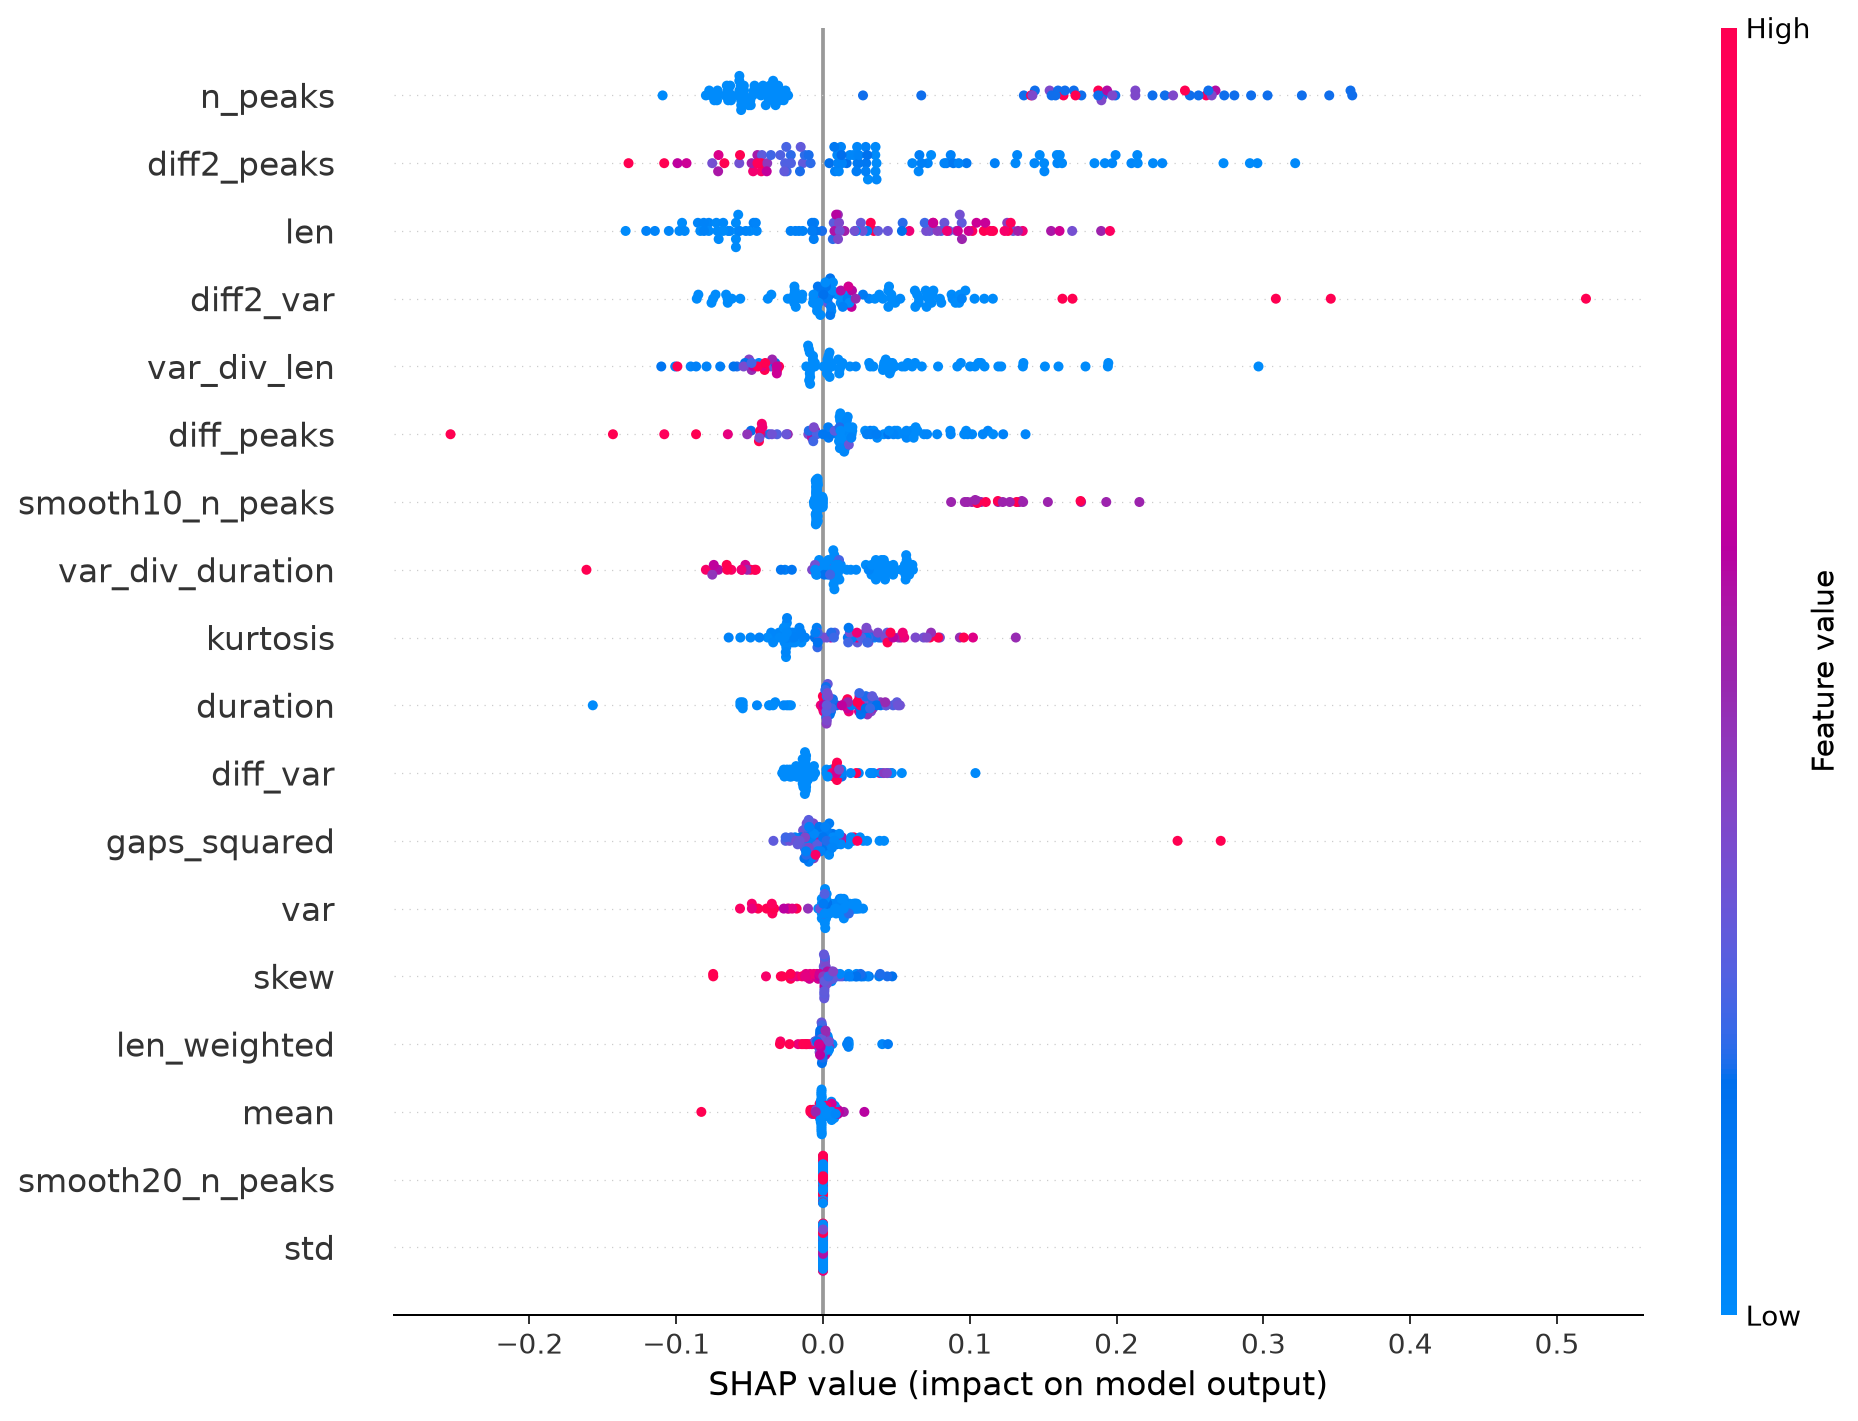

In [2]:
for figure_name, explanation in [
    ("shap_feature_importance.png", "Global importance: mean absolute SHAP contribution"),
    ("shap_summary.png", "SHAP summary: individual contributions and feature values"),
]:
    figure_path = FIGURES_DIR / figure_name
    print(explanation)
    display(Image(filename=str(figure_path)))

## 4. SHAP dependence plot

The dependence plot uses the globally highest-ranked feature. Each point is a test example; the x-axis is the feature's observed value and the y-axis is its SHAP contribution to the anomaly probability. The plot describes the model's learned pattern for these data. It does not show a causal or physical relationship.

Dependence plot feature: n_peaks


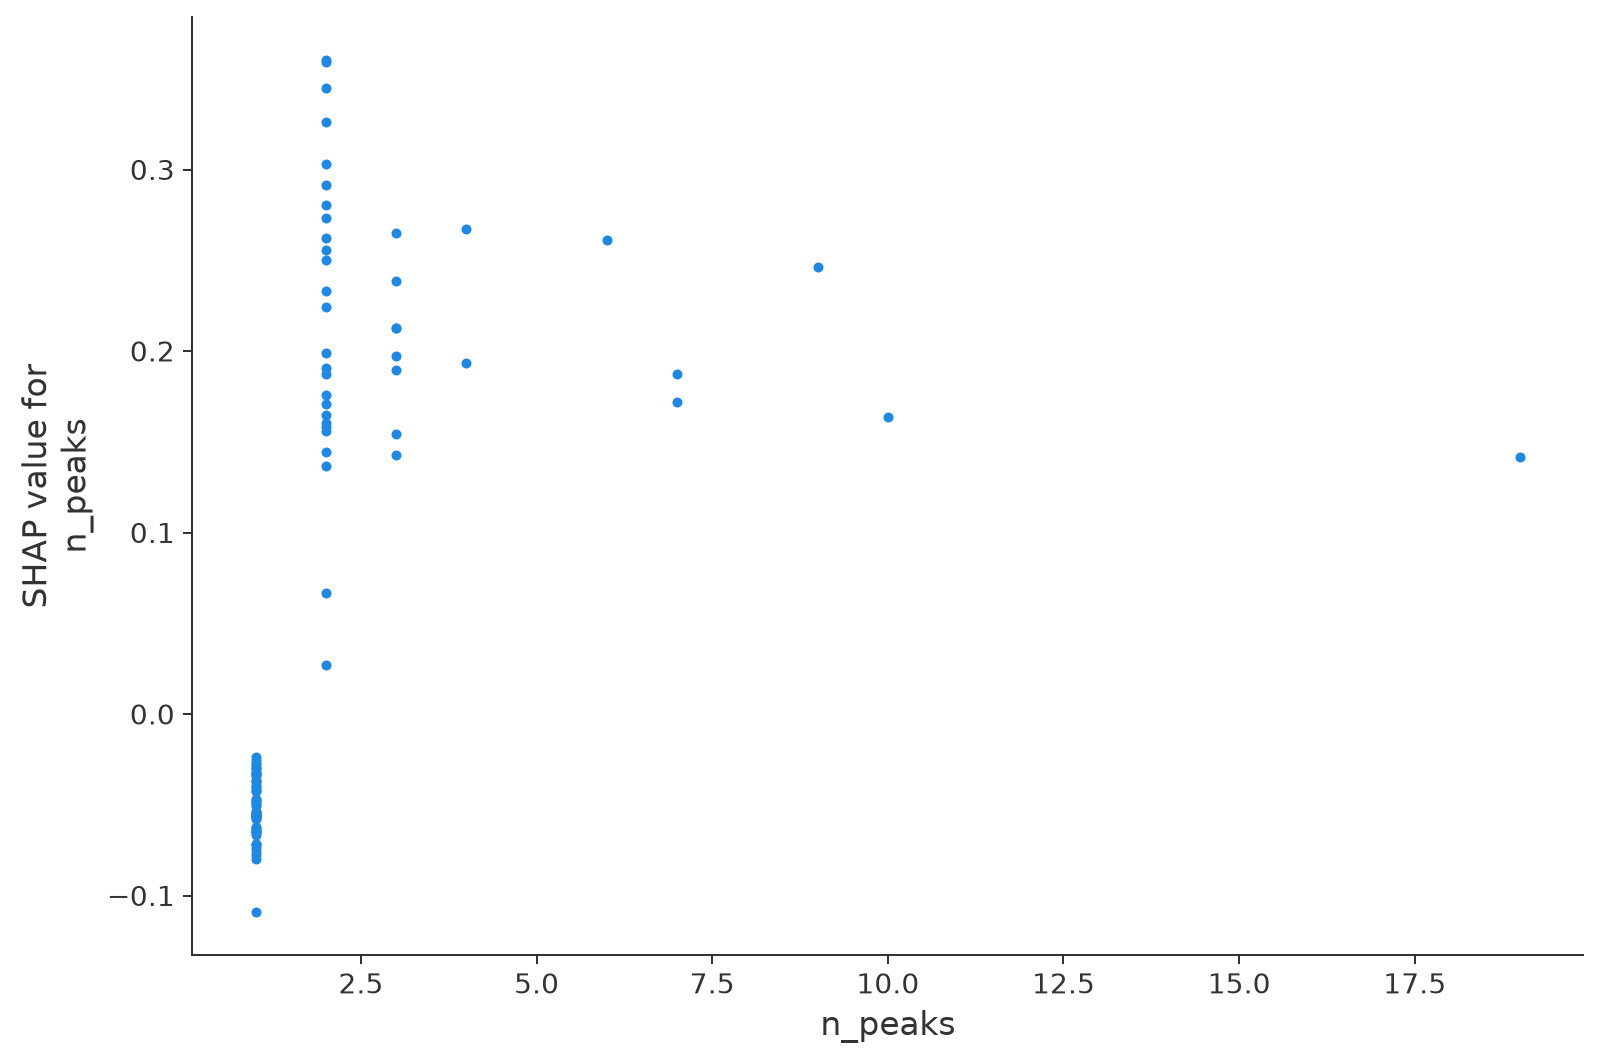

In [3]:
print("Dependence plot feature:", explanations["top_features"][0]["feature"])
display(Image(filename=str(FIGURES_DIR / "shap_dependence.png")))

## 5. Waterfall plots for one normal and one anomalous prediction

For both selected records, the actual and predicted classes agree: one is an actual normal predicted normal, the other an actual anomaly predicted anomalous. The waterfall begins at the model's baseline anomaly probability and adds positive/negative SHAP contributions to reconstruct the model's predicted class-1 probability. Local plots are selected from the official test set, not training data.

Normal example — segment 5; actual=0, predicted=0, P(anomaly)=0.0041.


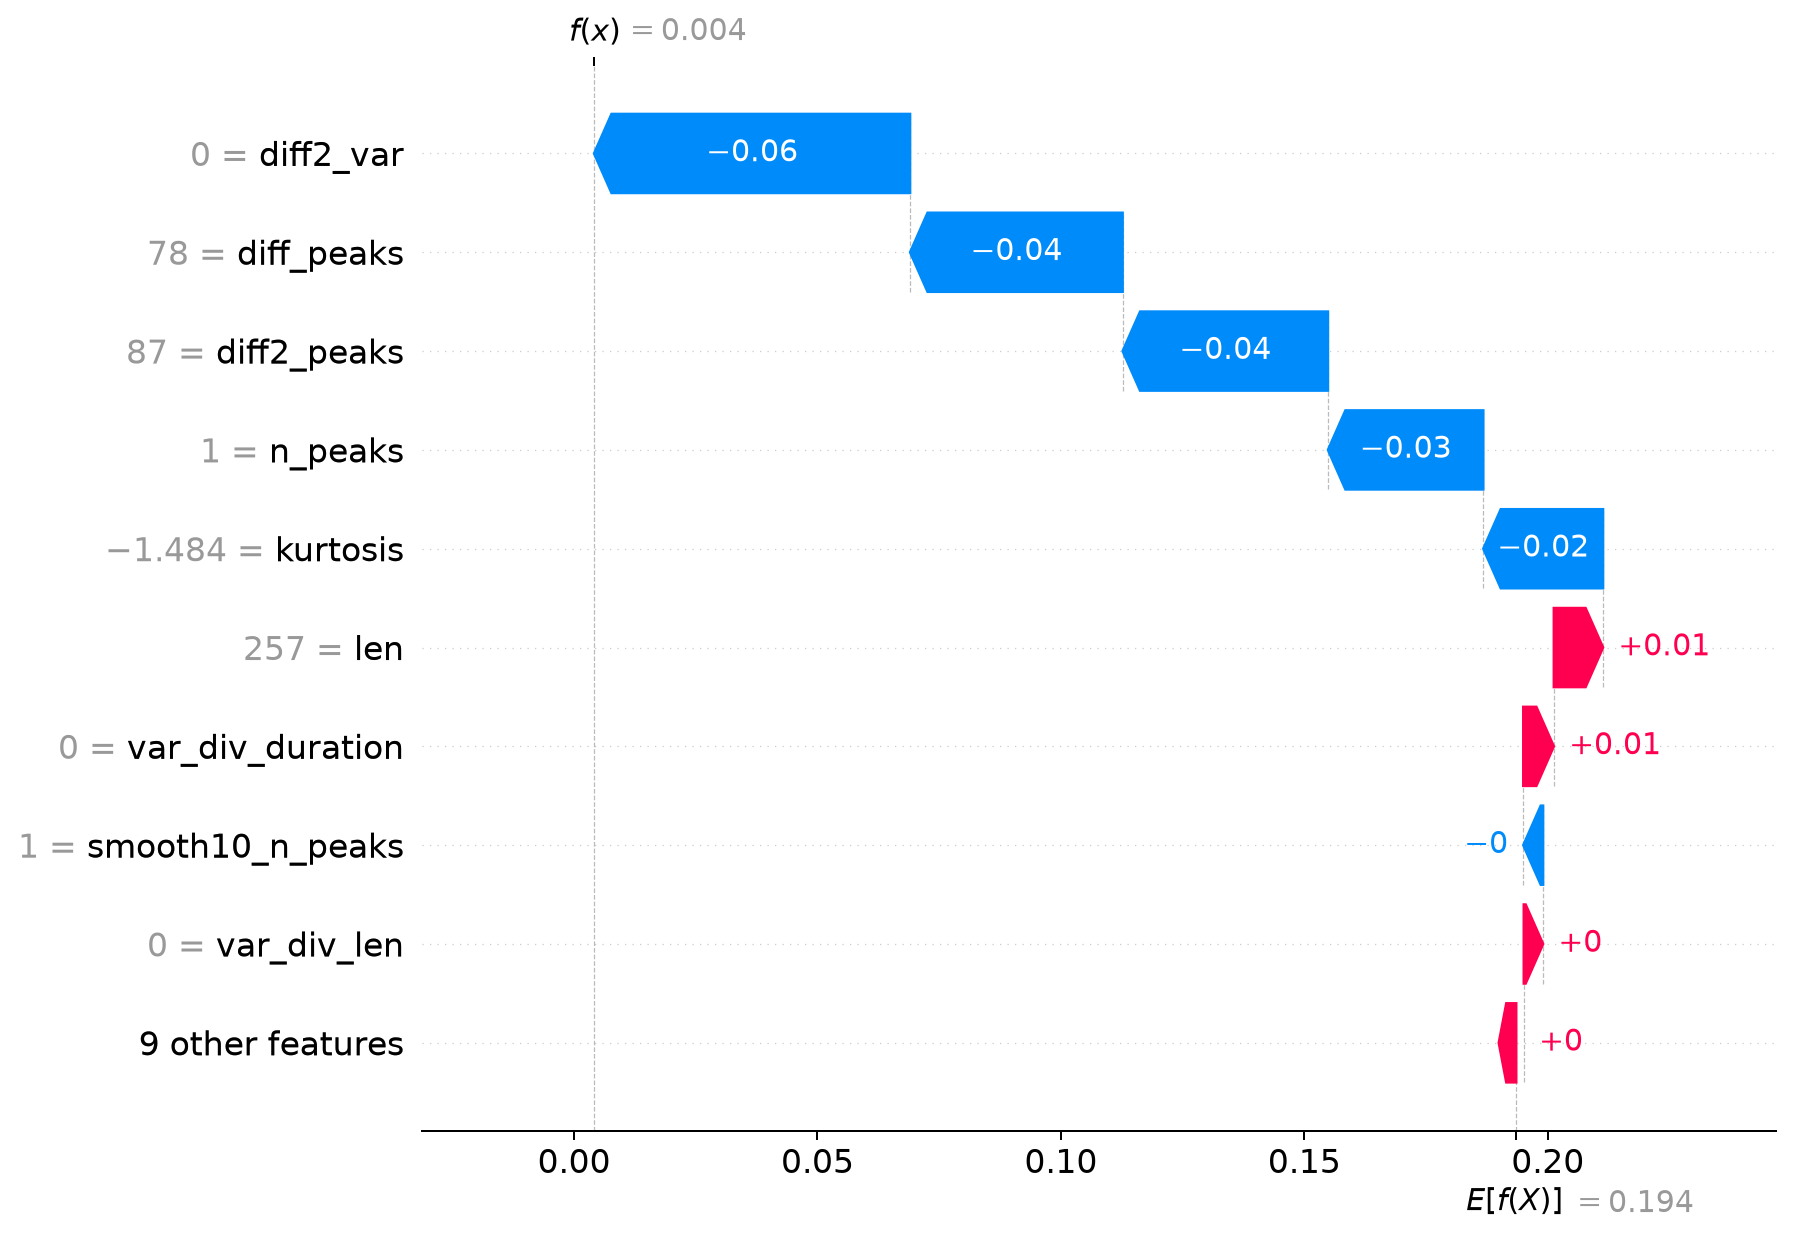

Anomalous example — segment 13; actual=1, predicted=1, P(anomaly)=0.9804.


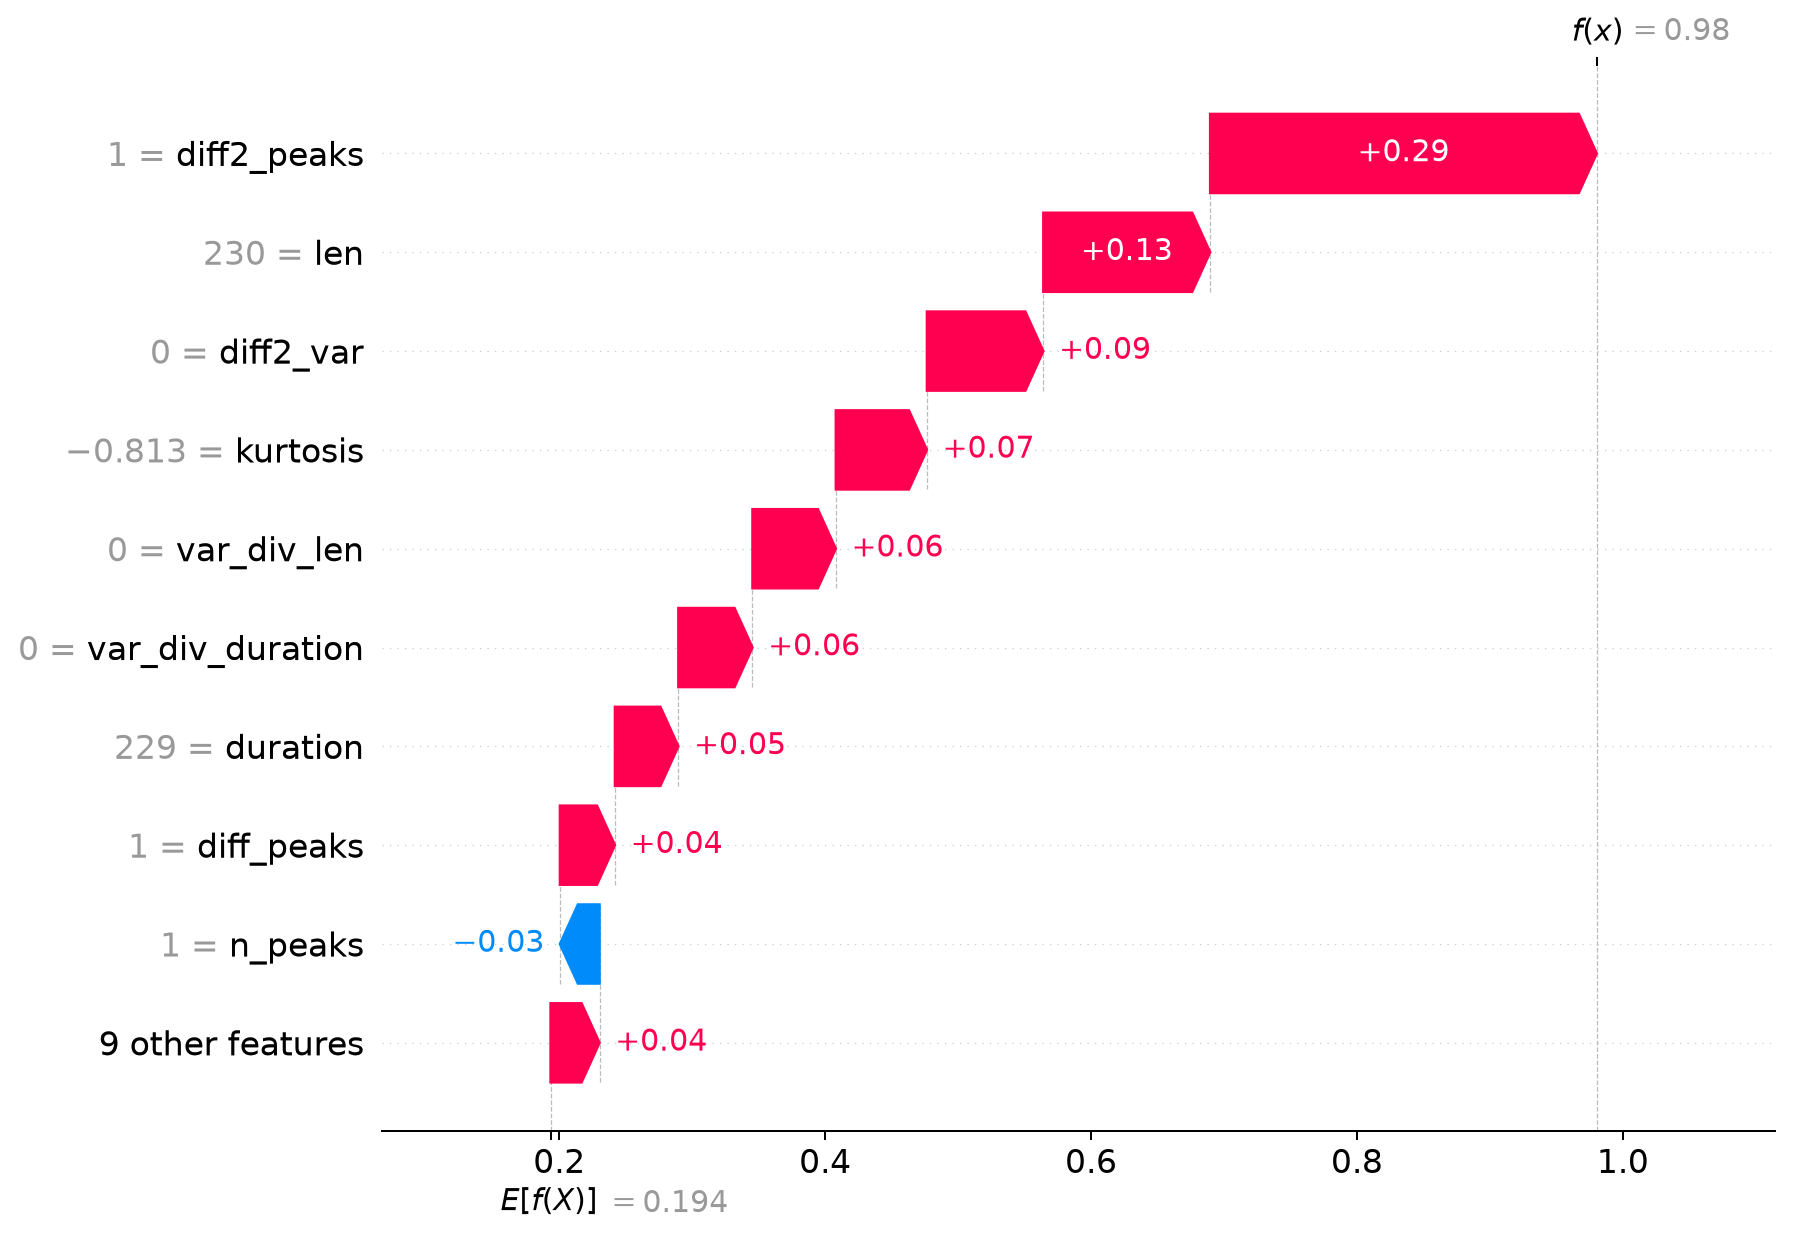

In [4]:
for kind, filename in [
    ("normal", "shap_normal_prediction.png"),
    ("anomalous", "shap_anomalous_prediction.png"),
]:
    local = explanations["selected_predictions"][kind]
    print(
        f"{kind.title()} example — segment {local.get('segment_id', 'unknown')}; "
        f"actual={local['actual_class']}, predicted={local['predicted_class']}, "
        f"P(anomaly)={local['predicted_anomaly_probability']:.4f}."
    )
    display(Image(filename=str(FIGURES_DIR / filename)))

## 6. Explain the top features and selected predictions

The following values come from the saved SHAP calculation. Mean absolute SHAP ranks contribution magnitude. Mean signed SHAP is the average direction over the selected sample: positive shifts toward an anomaly score and negative shifts away from it. Positive and negative individual contributions can occur for the same feature, so a global average is not a rule for every segment.

In [5]:
top_five = pd.DataFrame(explanations["top_features"])
display(top_five.round(6))
print("Top-five feature interpretation:")
for row in explanations["top_features"]:
    direction = (
        "on average shifts the model toward anomaly"
        if row["mean_signed_shap"] > 0
        else "on average shifts the model away from anomaly"
        if row["mean_signed_shap"] < 0
        else "has approximately balanced signed contributions"
    )
    print(
        f"- {row['feature']}: mean |SHAP|={row['mean_absolute_shap']:.4f}; "
        f"mean signed SHAP={row['mean_signed_shap']:+.4f}, which {direction} "
        "in this explained sample."
    )

for kind in ["normal", "anomalous"]:
    local = explanations["selected_predictions"][kind]
    assert local["actual_class"] == local["predicted_class"]
    assert abs(
        local["reconstructed_anomaly_probability"]
        - local["predicted_anomaly_probability"]
    ) < 2e-5
    print(
        f"\n{kind.title()} prediction (segment {local.get('segment_id', 'unknown')}): "
        f"actual/predicted class {local['actual_class']}; "
        f"P(anomaly)={local['predicted_anomaly_probability']:.4f}."
    )
    for contribution in local["top_contributions"][:3]:
        print(
            f"  {contribution['feature']}={contribution['feature_value']:.6g}: "
            f"SHAP {contribution['shap_value']:+.4f} ({contribution['direction']})."
        )

print("\nSHAP describes the model's behavior, not physical causation.")
required_files = [
    FIGURES_DIR / "shap_feature_importance.png",
    FIGURES_DIR / "shap_summary.png",
    FIGURES_DIR / "shap_dependence.png",
    FIGURES_DIR / "shap_normal_prediction.png",
    FIGURES_DIR / "shap_anomalous_prediction.png",
    SUMMARY_DIR / "shap_feature_importance.csv",
    SUMMARY_DIR / "shap_summary.json",
]
print("\nSaved SHAP outputs:")
for output_path in required_files:
    if not output_path.is_file() or output_path.stat().st_size == 0:
        raise FileNotFoundError(f"Expected SHAP output is missing or empty: {output_path}")
    print(f"- {output_path.relative_to(PROJECT_ROOT)} ({output_path.stat().st_size:,} bytes)")
print("\nStage 6 complete. No dashboard was created.")

,feature,mean_absolute_shap,mean_signed_shap
0,n_peaks,0.122186,0.064243
1,diff2_peaks,0.080179,0.048813
2,len,0.070011,0.019496
3,diff2_var,0.054146,0.033453
4,var_div_len,0.053443,0.019758


Top-five feature interpretation:
- n_peaks: mean |SHAP|=0.1222; mean signed SHAP=+0.0642, which on average shifts the model toward anomaly in this explained sample.
- diff2_peaks: mean |SHAP|=0.0802; mean signed SHAP=+0.0488, which on average shifts the model toward anomaly in this explained sample.
- len: mean |SHAP|=0.0700; mean signed SHAP=+0.0195, which on average shifts the model toward anomaly in this explained sample.
- diff2_var: mean |SHAP|=0.0541; mean signed SHAP=+0.0335, which on average shifts the model toward anomaly in this explained sample.
- var_div_len: mean |SHAP|=0.0534; mean signed SHAP=+0.0198, which on average shifts the model toward anomaly in this explained sample.

Normal prediction (segment 5): actual/predicted class 0; P(anomaly)=0.0041.
  diff2_var=7.03542e-13: SHAP -0.0649 (decreases the model's anomaly probability).
  diff_peaks=78: SHAP -0.0437 (decreases the model's anomaly probability).
  diff2_peaks=87: SHAP -0.0422 (decreases the model's anomaly prob